# SafeCool-CMDP demo

End-to-end walk-through of the safety-constrained offline RL baseline:
build buffer → train world model + agent → off-policy evaluate → roll out with shield → distill → shadow-mode deploy.

**Research baseline only.** Offline policy recommendations require human review and operational validation. Not a production deployment artifact.

In [1]:
# Hop to repo root if kernel started in notebooks/.
import os
from pathlib import Path
if Path.cwd().name == 'notebooks':
    os.chdir(Path.cwd().parent)
print('cwd:', Path.cwd())

cwd: /home/claude/project_03_safecool_cmdp


## 1. Explore the cooling environment

In [2]:
import numpy as np
from safecool.envs.lcopt_env import CoolingEnv, EnvConfig, ScenarioSpec, STATE_FIELDS, make_scenario

env = CoolingEnv(EnvConfig(episode_steps=48))
state = env.reset(make_scenario('nominal', seed=0))
print('Initial state:')
for name, v in zip(STATE_FIELDS, state):
    print(f'  {name:22s} = {v:7.3f}')

# Run a few steps under a zero action and watch dynamics.
for _ in range(5):
    state, reward, done, info = env.step(np.array([0.0, 0.0]))
print(f'After 5 steps  reward={reward:.3f}  inlet={state[STATE_FIELDS.index("inlet_temp_c")]:.2f}C  power={state[-1]:.2f}kW')

Initial state:
  fan_speed_pct          =  60.000
  coolant_supply_c       =  18.000
  inlet_temp_c           =  22.000
  outlet_temp_c          =  28.000
  cpu_load               =   0.246
  ambient_temp_c         =  15.019
  power_kw               =   4.126
After 5 steps  reward=-0.426  inlet=19.69C  power=4.26kW


## 2. Build the offline buffer

In [3]:
from safecool.data.build_offline_buffer import main as build_main
rc = build_main(['--base-config', 'configs/base.yaml',
                 '--env-config', 'configs/env_lcopt.yaml',
                 '--model-config', 'configs/model_cmdp.yaml'])
print('rc =', rc)

import numpy as np
with np.load('artifacts/offline_buffer.npz') as data:
    print('Buffer keys:', list(data.keys())[:10], '...')
    print('n_transitions:', data['state'].shape[0])
    print('action shape:', data['action'].shape)

Wrote buffer: artifacts/offline_buffer.npz (n_transitions=3456), manifest: artifacts/offline_buffer_manifest.json
rc = 0
Buffer keys: ['state', 'action', 'reward', 'next_state', 'done', 'cost', 'cost_inlet_hi', 'cost_inlet_lo', 'cost_outlet_hi', 'cost_rate_coolant'] ...
n_transitions: 3456
action shape: (3456, 2)


## 3. Inspect episode-level composition

In [4]:
import json, pandas as pd
manifest = json.load(open('artifacts/offline_buffer_manifest.json'))
df = pd.DataFrame(manifest)
print('Episodes:', len(df), '| policies:', df['policy'].nunique(), '| scenarios:', df['scenario_family'].nunique())
df.groupby(['policy', 'scenario_family'])[['mean_reward', 'sum_cost', 'max_inlet_c']].mean().round(3)

Episodes: 36 | policies: 3 | scenarios: 4


mean_reward  sum_cost  max_inlet_c
policy         scenario_family                                    
conservative   degradation           -0.750     0.000       21.879
               heatwave              -0.757     0.000       21.607
               nominal               -0.745     0.000       21.427
               spike                 -0.771     0.000       21.473
perturbed_safe degradation           -0.475     0.004       24.530
               heatwave              -0.419     0.585       24.677
               nominal               -0.314     0.447       24.322
               spike                 -0.337     1.139       24.424
rule_based     degradation           -0.387     0.000       24.805
               heatwave              -0.306     0.000       24.742
               nominal               -0.285     0.000       24.850
               spike                 -0.323     0.000       24.800

## 4. Train world model + CQL-lite agent + run OPE

In [5]:
from safecool.train import main as train_main
rc = train_main(['--base-config', 'configs/base.yaml',
                 '--env-config', 'configs/env_lcopt.yaml',
                 '--model-config', 'configs/model_cmdp.yaml'])
print('rc =', rc)

import json
report = json.load(open('artifacts/training_report.json'))
print(f'Buffer size: {report["n_transitions"]}')
print(f'FQE reward: {report["ope"]["fqe"]["reward_estimate"]:.3f}')
print(f'FQE cost:   {report["ope"]["fqe"]["cost_estimate"]:.3f}  (budget {report["budget_threshold"]:.2f})')
print(f'WIS reward: {report["ope"]["wis"]["reward_estimate"]:.3f}  CI [{report["ope"]["wis"]["reward_ci_low"]:.2f}, {report["ope"]["wis"]["reward_ci_high"]:.2f}]')
print(f'Gate: {"PASS" if report["ope_gate_pass"] else "FAIL"}')

03:36:44 [INFO] safecool.train: Loading existing buffer from artifacts/offline_buffer.npz


03:36:44 [INFO] safecool.train: Buffer size: 3456 transitions


03:36:50 [INFO] safecool.rl.offline_agent: agent ep=0 td_r=0.1225 td_c=0.0122 cql=3.223 lag=0.093 est_cost=-0.0272


03:36:50 [INFO] safecool.rl.offline_agent: agent ep=1 td_r=0.0869 td_c=0.0101 cql=3.241 lag=0.086 est_cost=-0.0281


03:36:50 [INFO] safecool.rl.offline_agent: agent ep=2 td_r=0.0740 td_c=0.0059 cql=3.232 lag=0.079 est_cost=-0.0373


03:36:50 [INFO] safecool.rl.offline_agent: agent ep=3 td_r=0.0683 td_c=0.0048 cql=3.207 lag=0.072 est_cost=-0.0357


... (24 outputs left out)

03:36:55 [INFO] safecool.rl.offline_agent: agent ep=28 td_r=0.1042 td_c=0.0023 cql=1.661 lag=0.000 est_cost=0.0033


03:36:56 [INFO] safecool.rl.offline_agent: agent ep=29 td_r=0.1014 td_c=0.0022 cql=1.656 lag=0.000 est_cost=0.0033


03:37:00 [INFO] safecool.train: Training complete. FQE reward=-15.557 cost=0.000 gate=PASS


rc = 0
Buffer size: 3456
FQE reward: -15.557
FQE cost:   0.000  (budget 1.92)
WIS reward: -10.899  CI [-12.87, -9.54]
Gate: PASS


## 5. Evaluate all policies across scenarios

In [6]:
from safecool.evaluate import main as eval_main
rc = eval_main(['--episodes', '3'])
import json, pandas as pd
report = json.load(open('artifacts/eval_report.json'))
agg = pd.DataFrame(report['aggregate_by_policy']).set_index('policy')
agg[['mean_reward', 'mean_energy_kw', 'mean_inlet_c', 'cvar95_inlet_c', 'viol_any', 'n_shield_intervened']].round(3)

03:37:03 [INFO] safecool.evaluate: Evaluation complete. shielded gate=PASS  unshielded gate=FAIL


,mean_reward,mean_energy_kw,mean_inlet_c,cvar95_inlet_c,viol_any,n_shield_intervened
policy,,,,,,
agent,-0.437,4.369,18.750,21.815,0.083,0.000
agent_shielded,-0.438,4.376,18.738,21.799,0.000,74.333
conservative,-0.757,7.570,17.109,21.066,0.000,0.000
rule_based,-0.317,3.167,23.880,24.675,0.000,0.000


## 6. Shield effect: compare agent vs agent+shield

In [7]:
import pandas as pd
ep = pd.read_csv('artifacts/eval_episodes.csv')
comparison = ep.groupby('policy').agg(
    mean_reward=('mean_reward', 'mean'),
    mean_energy=('mean_energy_kw', 'mean'),
    max_inlet=('max_inlet_c', 'max'),
    total_cost=('total_cost', 'mean'),
    violations=('viol_any', 'sum'),
    shield_per_ep=('n_shield_intervened', 'mean'),
).round(3)
comparison

,mean_reward,mean_energy,max_inlet,total_cost,violations,shield_per_ep
policy,,,,,,
agent,-0.437,4.369,27.179,0.021,1,0.000
agent_shielded,-0.438,4.376,26.915,0.000,0,74.333
conservative,-0.757,7.570,22.495,0.000,0,0.000
rule_based,-0.317,3.167,24.965,0.000,0,0.000


## 7. Plot inlet temperature trace for one episode per policy

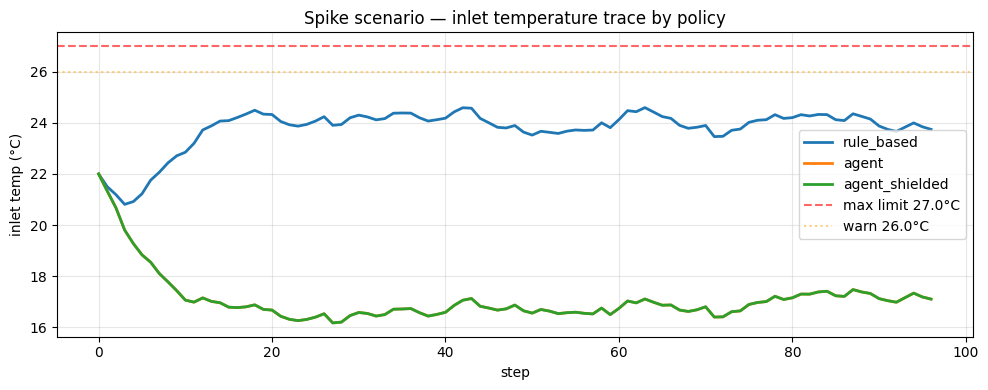

In [8]:
import matplotlib.pyplot as plt
import numpy as np
from safecool.envs.lcopt_env import CoolingEnv, env_config_from_dict, STATE_FIELDS, make_scenario
from safecool.envs.safety_constraints import SafetyConfig
from safecool.rl.offline_agent import load_agent
from safecool.rl.policy_shield import PolicyShield, conservative_fallback
from safecool.data.build_offline_buffer import POLICY_REGISTRY
from safecool.utils.config import load_configs

cfg = load_configs('configs/base.yaml', 'configs/env_lcopt.yaml', 'configs/model_cmdp.yaml')
env_cfg = env_config_from_dict(cfg)
env_cfg.episode_steps = 96
safety = SafetyConfig.from_dict(cfg)
agent = load_agent('artifacts/agent.pt')

def rollout(act_fn, scenario_seed=0):
    env = CoolingEnv(env_cfg)
    s = env.reset(make_scenario('spike', seed=scenario_seed))
    trace = [float(s[STATE_FIELDS.index('inlet_temp_c')])]
    while True:
        a = np.asarray(act_fn(s), dtype=np.float32)
        s, r, done, _ = env.step(a)
        trace.append(float(s[STATE_FIELDS.index('inlet_temp_c')]))
        if done: break
    return trace

rng = np.random.default_rng(0)
rb_policy = POLICY_REGISTRY['rule_based']
rule_act = lambda st: rb_policy.sample(st, rng)[0]
agent_act = lambda st: agent.predict(st)

shield = PolicyShield(safety_cfg=safety, fallback_policy=conservative_fallback, use_lookahead=False)
def shielded_act(st):
    return shield(agent.predict(st), st)['action']

traces = {
    'rule_based': rollout(rule_act),
    'agent': rollout(agent_act),
    'agent_shielded': rollout(shielded_act),
}
fig, ax = plt.subplots(figsize=(10, 4))
for name, t in traces.items():
    ax.plot(t, label=name, lw=2)
ax.axhline(safety.max_inlet_temp_c, color='red', ls='--', alpha=0.6, label=f'max limit {safety.max_inlet_temp_c}°C')
ax.axhline(safety.inlet_warn_c, color='orange', ls=':', alpha=0.5, label=f'warn {safety.inlet_warn_c}°C')
ax.set_xlabel('step'); ax.set_ylabel('inlet temp (°C)')
ax.set_title('Spike scenario — inlet temperature trace by policy')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 8. Distill the agent into interpretable decision-tree rules

In [9]:
from safecool.distill import main as distill_main
rc = distill_main(['--max-depth', '4'])

import json
info = json.load(open('artifacts/surrogate.json'))
print(f'Fidelity on held-out states: {info["fidelity_holdout"]}')
print('--- first 30 lines of surrogate.txt ---')
print('\n'.join(open('artifacts/surrogate.txt').read().splitlines()[:30]))

03:37:09 [INFO] safecool.distill: Surrogate fidelity agreement=0.955  mae_coolant=0.026  mae_fan=0.075


Fidelity on held-out states: {'mae_coolant': 0.025729513123622517, 'mae_fan': 0.075, 'agreement_within_half_grid': 0.955}
--- first 30 lines of surrogate.txt ---
# SafeCool-CMDP distilled surrogate

Each tree approximates the trained agent's greedy action for one control dimension.
These rules are an interpretable approximation intended for human review only.

## Coolant supply delta (°C)

|--- coolant_supply_c <= 19.03
|   |--- inlet_temp_c <= 22.02
|   |   |--- power_kw <= 3.97
|   |   |   |--- cpu_load <= 0.21
|   |   |   |   |--- value: [0.00]
|   |   |   |--- cpu_load >  0.21
|   |   |   |   |--- value: [-0.50]
|   |   |--- power_kw >  3.97
|   |   |   |--- value: [-0.50]
|   |--- inlet_temp_c >  22.02
|   |   |--- fan_speed_pct <= 84.06
|   |   |   |--- value: [0.00]
|   |   |--- fan_speed_pct >  84.06
|   |   |   |--- value: [-0.50]
|--- coolant_supply_c >  19.03
|   |--- inlet_temp_c <= 22.55
|   |   |--- outlet_temp_c <= 22.12
|   |   |   |--- value: [-0.50]
|   |   |--- outle

## 9. Shadow-mode deploy with audit log and rollback rules

In [10]:
from safecool.deploy import main as deploy_main
rc = deploy_main(['--scenario', 'heatwave'])

import json
report = json.load(open('artifacts/deploy_report.json'))
print(f'Scenario: {report["scenario_family"]}')
print(f'Steps: {report["n_steps"]}  max_inlet={report["max_inlet_c"]:.2f}C  CVaR-95={report["cvar95_inlet_c"]:.2f}C')
print(f'Shield interventions: {report["n_shield_interventions"]}')
print(f'Rollback active: {report["rollback_active"]}  reason={report["rollback_reason"]}')
print(f'Agent checkpoint SHA-256: {report["agent_checkpoint_sha256"][:32]}...')
print()
print('Disclaimer:', report['disclaimer'])

03:37:10 [INFO] safecool.deploy: Shadow run complete. rollback=False  max_inlet=21.34C  interventions=89  → artifacts/deploy_report.json


Scenario: heatwave
Steps: 96  max_inlet=21.34C  CVaR-95=20.85C
Shield interventions: 89
Rollback active: False  reason=None
Agent checkpoint SHA-256: b1e8ef2148b9fda289127e8cc290a05d...

Disclaimer: Shadow-mode simulation output. Not a production deployment artifact. Policies require human review and operational validation before live use.
